# 6.4 - Trực quan hóa luật kết hợp (Association Rules Visualization)
**Họ và tên:** Thái Anh Lạc | **MSSV:** 089206000860 | **Mã lớp HP:** 012012204103  

In [1]:
# 1. Trích xuất các luật kết hợp từ dữ liệu Market-Basket
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import networkx as nx
from fim import arules

# Dữ liệu Market-Basket từ các bài trước
dataset = [
    ['Bread', 'Milk'],
    ['Bread', 'Diaper', 'Beer', 'Eggs'],
    ['Milk', 'Diaper', 'Beer', 'Coke'],
    ['Bread', 'Milk', 'Diaper', 'Beer'],
    ['Bread', 'Milk', 'Diaper', 'Coke']
]

# Trích xuất luật với minSup = 40% (2/5 giao dịch) và minConf = 60%
raw_rules = arules(dataset, supp=40, conf=60, zmin=2, report='asCl')

data = []
for head, body, sup_cnt, sup_frac, conf_pct, lift_val in raw_rules:
    data.append({
        'antecedants': list(body),
        'consequents': [head],
        'support': sup_frac,
        'confidence': conf_pct / 100.0,
        'lift': round(lift_val, 3),
        'rule': f"{set(body)} -> {{{head}}}"
    })

df_rules = pd.DataFrame(data).sort_values(by=['confidence', 'lift', 'support'], ascending=False).reset_index(drop=True)

print(f"Tổng số luật kết hợp tìm được: {len(df_rules)}")
display(df_rules.head(10))

Tổng số luật kết hợp tìm được: 24


,antecedants,consequents,support,confidence,lift,rule
0,[Beer],[Diaper],0.6,1.00,1.250,{'Beer'} -> {Diaper}
1,"[Beer, Milk]",[Diaper],0.4,1.00,1.250,"{'Beer', 'Milk'} -> {Diaper}"
2,"[Beer, Bread]",[Diaper],0.4,1.00,1.250,"{'Beer', 'Bread'} -> {Diaper}"
3,[Coke],[Diaper],0.4,1.00,1.250,{'Coke'} -> {Diaper}
4,"[Coke, Milk]",[Diaper],0.4,1.00,1.250,"{'Coke', 'Milk'} -> {Diaper}"
5,"[Coke, Diaper]",[Milk],0.4,1.00,1.250,"{'Diaper', 'Coke'} -> {Milk}"
6,[Coke],[Milk],0.4,1.00,1.250,{'Coke'} -> {Milk}
7,[Diaper],[Beer],0.6,0.75,1.250,{'Diaper'} -> {Beer}
8,[Milk],[Diaper],0.6,0.75,0.938,{'Milk'} -> {Diaper}
9,[Diaper],[Milk],0.6,0.75,0.938,{'Diaper'} -> {Milk}


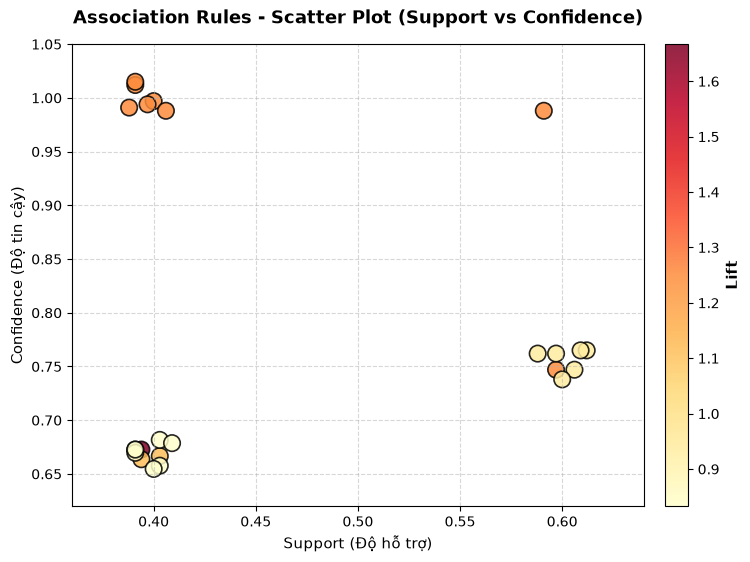

In [ ]:
# 2. Biểu đồ phân tán Scatter Plot (Support vs Confidence)
# Thêm độ lệch ngẫu nhiên nhỏ (jitter) như tác giả hướng dẫn để các điểm trùng tọa độ tách rời rõ ràng

random.seed(42)
support = list(df_rules['support'])
confidence = list(df_rules['confidence'])

# Kỹ thuật jitter từ bài viết: giúp nhìn rõ các điểm dữ liệu trùng tọa độ
for i in range(len(support)):
    support[i] = support[i] + 0.003 * (random.randint(1, 10) - 5)
    confidence[i] = confidence[i] + 0.003 * (random.randint(1, 10) - 5)

plt.figure(figsize=(9, 6))

# Vẽ biểu đồ phân tán, màu sắc thể hiện giá trị Lift
sc = plt.scatter(
    support, confidence,
    c=df_rules['lift'],
    cmap='YlOrRd',
    s=140,
    edgecolors='black',
    linewidth=1.2,
    alpha=0.85
)

cbar = plt.colorbar(sc, pad=0.03)
cbar.set_label('Lift', fontsize=11, weight='bold')

plt.title('Association Rules - Scatter Plot (Support vs Confidence)', fontsize=13, weight='bold', pad=15)
plt.xlabel('Support (Độ hỗ trợ)', fontsize=11)
plt.ylabel('Confidence (Độ tin cậy)', fontsize=11)

# Mở rộng khoảng hiển thị để biểu đồ thoáng đãng, không bị chật chội
plt.xlim(0.36, 0.64)
plt.ylim(0.62, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

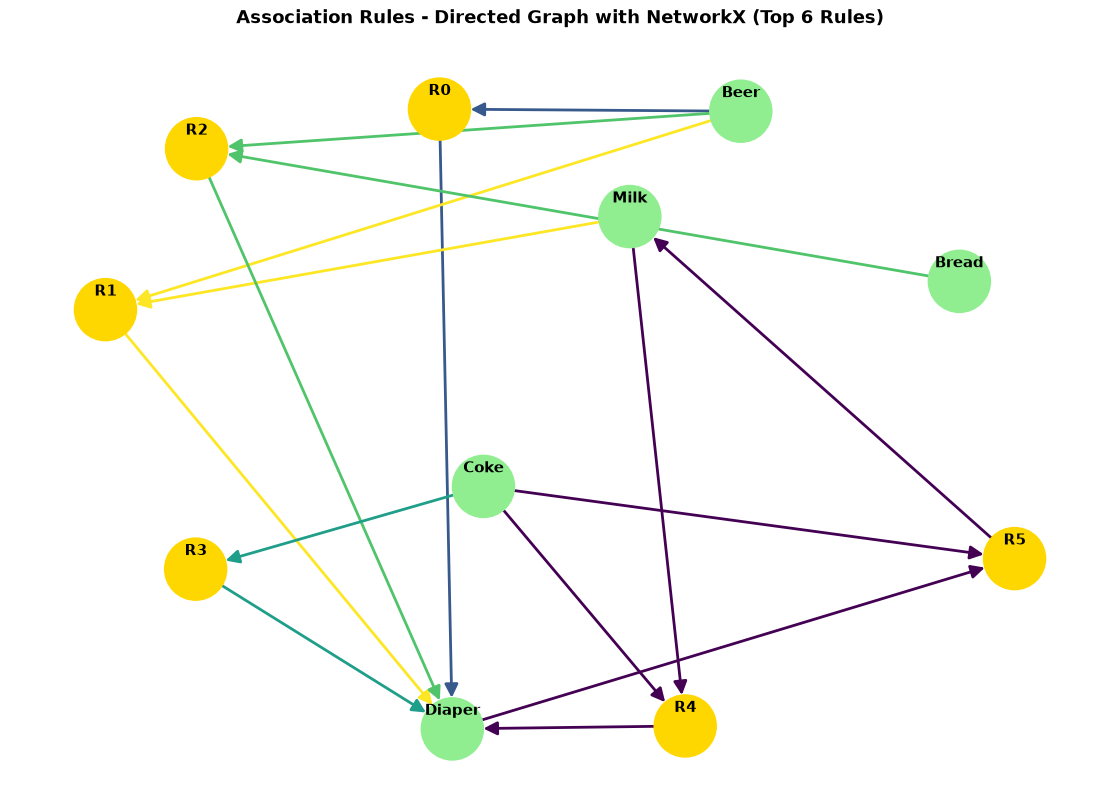

=== BẢNG CHÚ GIẢI CÁC NÚT LUẬT TRÊN ĐỒ THỊ ===
  R0: {'Beer'} -> {Diaper}           | Support = 0.6 | Confidence = 100% | Lift = 1.25
  R1: {'Beer', 'Milk'} -> {Diaper}   | Support = 0.4 | Confidence = 100% | Lift = 1.25
  R2: {'Beer', 'Bread'} -> {Diaper}  | Support = 0.4 | Confidence = 100% | Lift = 1.25
  R3: {'Coke'} -> {Diaper}           | Support = 0.4 | Confidence = 100% | Lift = 1.25
  R4: {'Coke', 'Milk'} -> {Diaper}   | Support = 0.4 | Confidence = 100% | Lift = 1.25
  R5: {'Diaper', 'Coke'} -> {Milk}   | Support = 0.4 | Confidence = 100% | Lift = 1.25


In [ ]:
# 3. Đồ thị mạng có hướng (Directed Graph) bằng NetworkX
# Biểu diễn các mặt hàng là nút Xanh lá, các luật là nút Vàng (R0, R1,...), nối bằng mũi tên có hướng

def draw_graph(rules, rules_to_show=6):
    G1 = nx.DiGraph()
    color_map = []
    N = 50
    np.random.seed(42)
    colors = np.random.rand(N)
    strs = [f"R{i}" for i in range(rules_to_show)]
    
    for i in range(rules_to_show):
        r_node = f"R{i}"
        G1.add_node(r_node)
        
        # Nối từ Tiền đề (Antecedants) -> Nút luật
        for a in rules.iloc[i]['antecedants']:
            G1.add_node(a)
            G1.add_edge(a, r_node, color=colors[i], weight=2)
            
        # Nối từ Nút luật -> Hệ quả (Consequents)
        for c in rules.iloc[i]['consequents']:
            G1.add_node(c)
            G1.add_edge(r_node, c, color=colors[i], weight=2)
            
    # Phân màu nút theo đúng code bài viết: Nút luật = Vàng (Gold), Nút mặt hàng = Xanh lá (Lightgreen)
    for node in G1:
        if node in strs:
            color_map.append('gold')
        else:
            color_map.append('lightgreen')
            
    edges = list(G1.edges())
    edge_colors = [G1[u][v]['color'] for u, v in edges]
    weights = [G1[u][v]['weight'] for u, v in edges]
    
    plt.figure(figsize=(11, 7.5))
    
    # Bố cục mạng lưới rộng rãi k=2.0 để các nhãn không bị đè lên nhau
    pos = nx.spring_layout(G1, k=2.0, scale=1.0, seed=42)
    
    # Vẽ các nút và cạnh có hướng
    nx.draw(
        G1, pos,
        edgelist=edges,
        node_color=color_map,
        edge_color=edge_colors,
        width=weights,
        node_size=2000,
        with_labels=False,
        arrows=True,
        arrowsize=20
    )
    
    # Nâng vị trí nhãn lên một chút như bài viết hướng dẫn để chữ nằm rõ trong/trên nút
    pos_labels = {p: (coords[0], coords[1] + 0.05) for p, coords in pos.items()}
    nx.draw_networkx_labels(G1, pos_labels, font_size=11, font_weight='bold')
    
    plt.title(f"Association Rules - Directed Graph with NetworkX (Top {rules_to_show} Rules)", fontsize=13, weight='bold', pad=15)
    plt.axis('off')
    plt.show()

# Gọi hàm hiển thị 6 luật tiêu biểu nhất
draw_graph(df_rules, rules_to_show=6)

# In bảng chú giải danh sách các nút luật R0 -> R5 tương ứng
print("=== BẢNG CHÚ GIẢI CÁC NÚT LUẬT TRÊN ĐỒ THỊ ===")
for i in range(6):
    r = df_rules.iloc[i]
    print(f"  R{i}: {r['rule']:<30} | Support = {r['support']} | Confidence = {r['confidence']*100:.0f}% | Lift = {r['lift']}")